## Домашнее задание 2. Решающие деревья

### О задании

Задание было адаптировано из курса по машинному обучению Е.А. Соколова.

### Оценивание и штрафы
Каждая из частей задания имеет определенную «стоимость» (указана в скобках около названия части). Максимально допустимая оценка за работу — 5 баллов. Помимо концептуальных ошибок и отсутствия решения, оценка может быть снижена за неэффективную реализацию или неопрятные графики.

**Обратите внимание**, что в каждом разделе домашнего задания есть оцениваемые задачи и есть вопросы. Вопросы дополняют задачи и направлены на то, чтобы проинтерпретировать или обосновать происходящее. Код без интерпретации не имеет смысла, поэтому отвечать на вопросы обязательно — за отсутствие ответов баллы будут снижены. Если вы ответите на вопросы, но не напишете корректный код к соответствующим оцениваемым задачам, то баллы за такое выставлены не будут.

### Формат сдачи
Задания сдаются через ваш приватный гит репозиторий. Туда необходимо сложить ноутбук с вашим решением и модуль `hw2code.py` с реализованными функциями и классами.

In [ ]:
# Импорты всякие 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, make_scorer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from hw2code import DecisionTree, find_best_split

%matplotlib inline

sns.set_theme(style='whitegrid',font='DejaVu Sans')
SEED=42

## Часть 1. Решающие деревья: визуализация (1.5 балла)

В этой части рассмотрим три простых двумерных датасета, сделанных с помощью `make_circles`, `make_moons` и `make_classification`, и посмотрим, как ведет себя разделяющая поверхность в зависимости от различных гиперпараметров.

In [2]:
from sklearn.datasets import make_moons, make_circles, make_classification

datasets = [
    make_circles(noise=0.2, factor=0.5, random_state=42),
    make_moons(noise=0.2, random_state=42),
    make_classification(n_classes=3, n_clusters_per_class=1, n_features=2, class_sep=.8, random_state=3,
                        n_redundant=0),
]

In [3]:
palette = sns.color_palette(n_colors=3)
cmap = ListedColormap(palette)

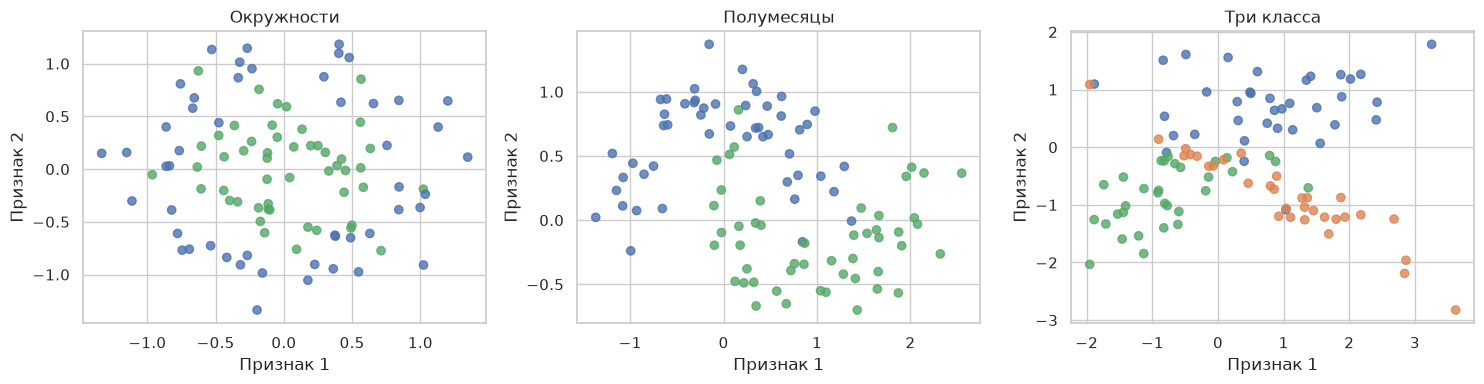

In [4]:
names=['Окружности','Полумесяцы','Три класса']
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,name,(X,y) in zip(axes,names,datasets):
    ax.scatter(X[:,0],X[:,1],c=y,cmap=cmap,alpha=.8)
    ax.set(title=name,xlabel='Признак 1',ylabel='Признак 2')
plt.tight_layout()
plt.show()

**Задание 1**. Для каждого датасета обучите решающее дерево с параметрами по умолчанию, предварительно разбив выборку на обучающую и тестовую. Постройте разделяющие поверхности (для этого воспользуйтесь функцией `plot_surface`, пример ниже). Посчитайте accuracy на обучающей и тестовой выборках.

In [5]:
def plot_surface(clf, X, y):
    plot_step = 0.01
    palette = sns.color_palette(n_colors=len(np.unique(y)))
    cmap = ListedColormap(palette)
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, plot_step),
                         np.arange(y_min, y_max, plot_step))
    plt.tight_layout(h_pad=0.5, w_pad=0.5, pad=2.5)

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    cs = plt.contourf(xx, yy, Z, cmap=cmap, alpha=0.3)

    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap, alpha=.7,
                edgecolors=np.array(palette)[y], linewidths=2)

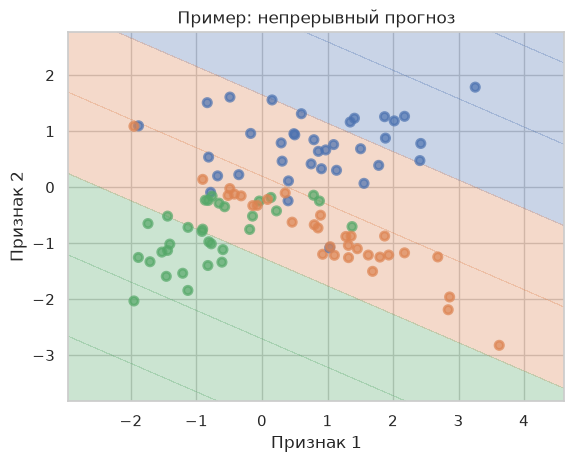

In [6]:
# Пример:
from sklearn.linear_model import LinearRegression
X,y=datasets[2]
lr=LinearRegression().fit(X,y)
plot_surface(lr,X,y)

plt.xlabel('Признак 1')
plt.ylabel('Признак 2')
plt.title('Пример: непрерывный прогноз')
plt.show()

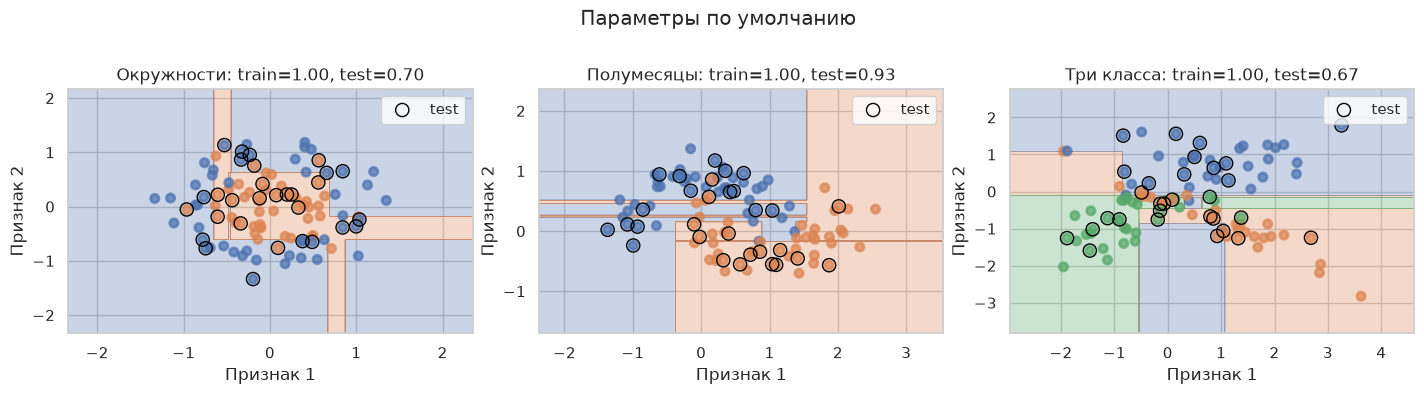

,train accuracy,test accuracy,train error,test error,baseline,глубина
датасет,,,,,,
Окружности,1.0,0.700,0.0,0.300,0.500,6
Полумесяцы,1.0,0.933,0.0,0.067,0.500,6
Три класса,1.0,0.667,0.0,0.333,0.367,6


In [7]:
splits=[train_test_split(X,y,test_size=.3,stratify=y,random_state=SEED) for X,y in datasets]
def experiment(params):
    rows=[]
    plt.figure(figsize=(15,4))
    
    for i,(name,(X_train,X_test,y_train,y_test)) in enumerate(zip(names,splits)):
        model=DecisionTreeClassifier(random_state=SEED,**params).fit(X_train,y_train)
        baseline=DummyClassifier(strategy='most_frequent').fit(X_train,y_train)
        train_acc=accuracy_score(y_train,model.predict(X_train))
        test_acc=accuracy_score(y_test,model.predict(X_test))
        rows.append({'датасет':name,'train accuracy':train_acc,'test accuracy':test_acc,'train error':1-train_acc,'test error':1-test_acc,'baseline':baseline.score(X_test,y_test),'глубина':model.get_depth()})
        plt.subplot(1,3,i+1)
        plot_surface(model,np.vstack([X_train,X_test]),np.r_[y_train,y_test])
        plt.scatter(X_test[:,0],X_test[:,1],facecolors='none',edgecolors='black',s=90,label='test')
        plt.xlabel('Признак 1');plt.ylabel('Признак 2')
        plt.title(f'{name}: train={train_acc:.2f}, test={test_acc:.2f}')
        plt.legend()

    plt.suptitle(str(params) if params else 'Параметры по умолчанию',y=1.04)
    plt.show()

    return pd.DataFrame(rows).set_index('датасет')
    
default_results=experiment({})
display(default_results.round(3))

**Вопрос**: Сильно ли деревья переобучились?

**Ответ** На train у всех трёх деревьев accuracy=1. На test: окружности — 0.70, полумесяцы — 0.933, три класса — 0.667.

На окружностях и трёх классах разрыв большой, дерево явно подстроилось под обучающие точки. На полумесяцах разрыв меньше. Но test маленький (30 объектов), поэтому по одному разбиению какой-то определенный вывод о поведении на любых данных я бы не делал

**Задание 2**. Попробуйте перебрать несколько параметров для регуляризации (напр. `max_depth`, `min_samples_leaf`). Для каждого набора гиперпараметров постройте разделяющую поверхность, выведите обучающую и тестовую ошибки. Можно делать кросс-валидацию или просто разбиение на трейн и тест, главное делайте каждый раз одинаковое разбиение, чтобы можно было корректно сравнивать (помним, что дерево сильно зависит от небольшого изменения обучающей выборки). Проследите, как меняются разделяющая поверхность и обобщающая способность.

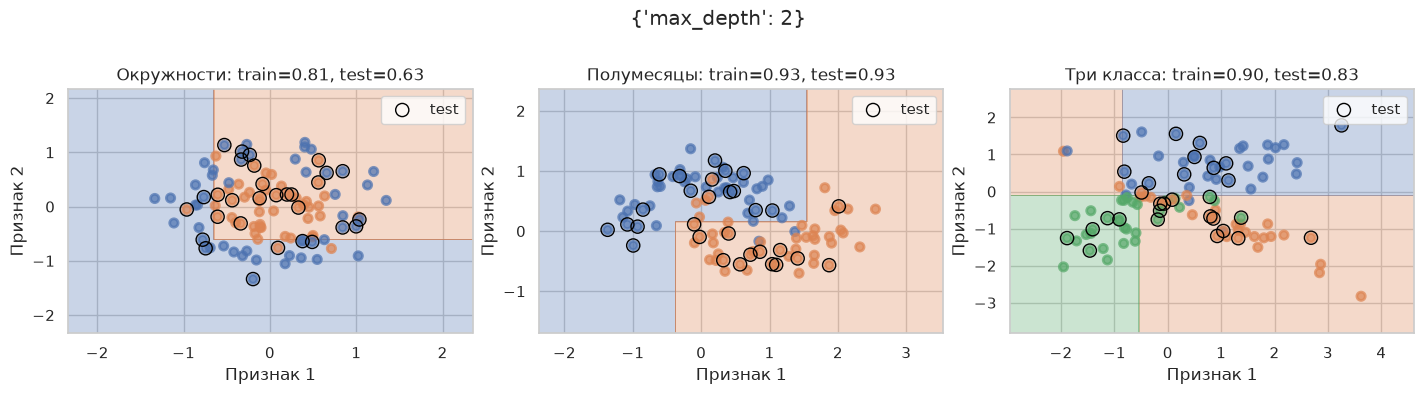

,train accuracy,test accuracy,train error,test error,baseline,глубина
датасет,,,,,,
Окружности,0.814,0.633,0.186,0.367,0.500,2
Полумесяцы,0.929,0.933,0.071,0.067,0.500,2
Три класса,0.900,0.833,0.100,0.167,0.367,2


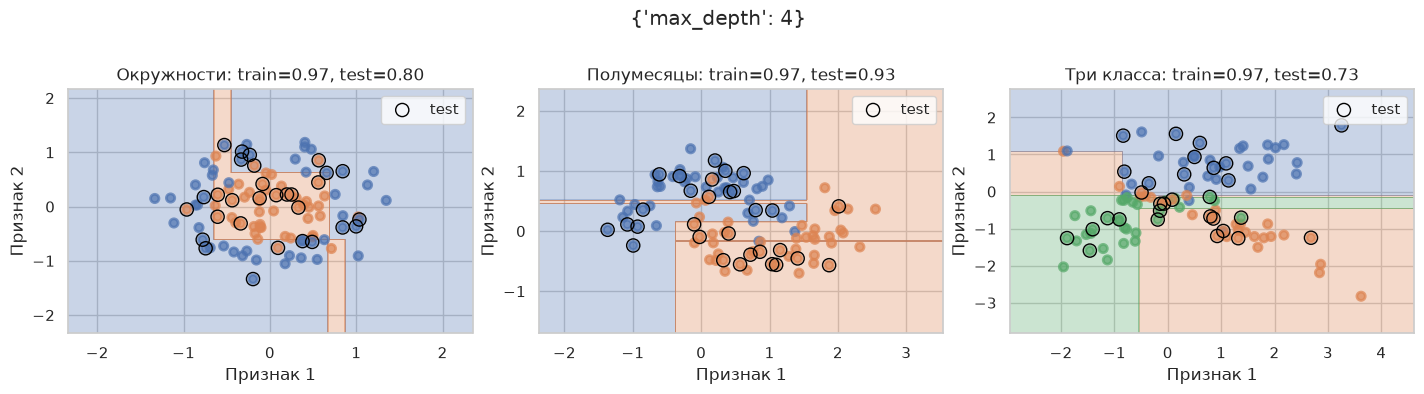

,train accuracy,test accuracy,train error,test error,baseline,глубина
датасет,,,,,,
Окружности,0.971,0.800,0.029,0.200,0.500,4
Полумесяцы,0.971,0.933,0.029,0.067,0.500,4
Три класса,0.971,0.733,0.029,0.267,0.367,4


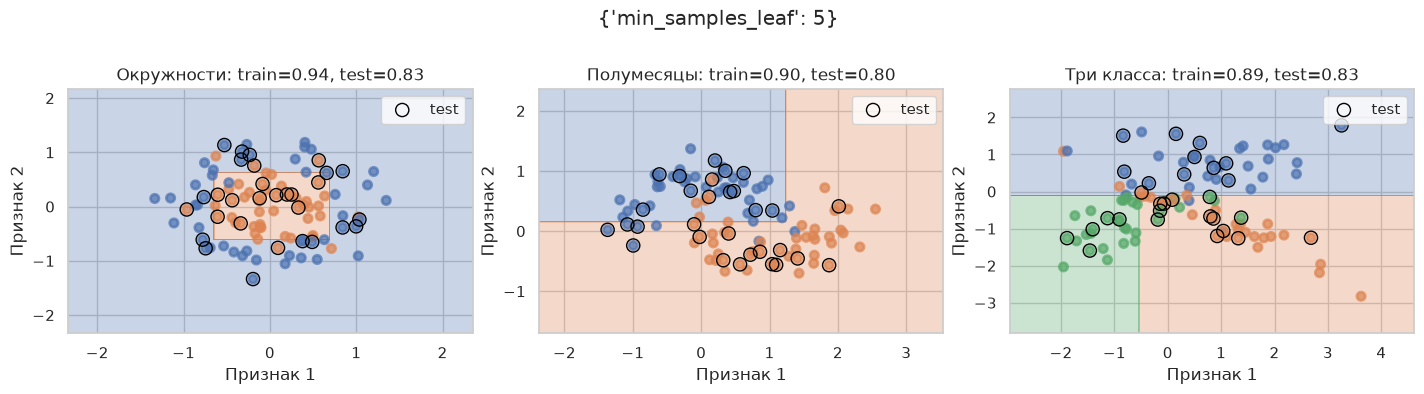

,train accuracy,test accuracy,train error,test error,baseline,глубина
датасет,,,,,,
Окружности,0.943,0.833,0.057,0.167,0.500,5
Полумесяцы,0.900,0.800,0.100,0.200,0.500,4
Три класса,0.886,0.833,0.114,0.167,0.367,4


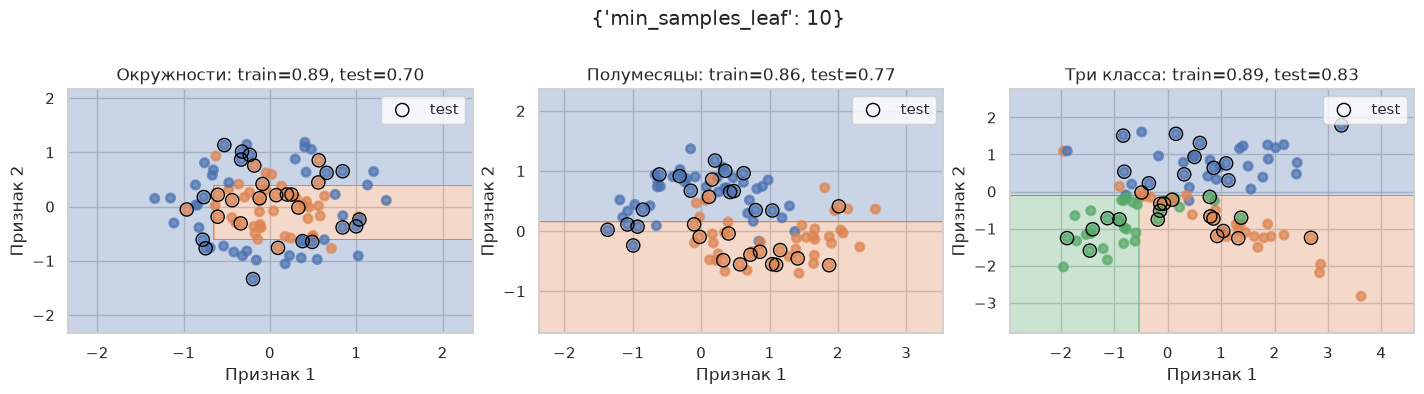

,train accuracy,test accuracy,train error,test error,baseline,глубина
датасет,,,,,,
Окружности,0.886,0.700,0.114,0.300,0.500,4
Полумесяцы,0.857,0.767,0.143,0.233,0.500,3
Три класса,0.886,0.833,0.114,0.167,0.367,3


,датасет,параметры,train error,test error
0,Окружности,по умолчанию,0.000,0.300
1,Полумесяцы,по умолчанию,0.000,0.067
2,Три класса,по умолчанию,0.000,0.333
3,Окружности,{'max_depth': 2},0.186,0.367
4,Полумесяцы,{'max_depth': 2},0.071,0.067
5,Три класса,{'max_depth': 2},0.100,0.167
6,Окружности,{'max_depth': 4},0.029,0.200
7,Полумесяцы,{'max_depth': 4},0.029,0.067
8,Три класса,{'max_depth': 4},0.029,0.267
9,Окружности,{'min_samples_leaf': 5},0.057,0.167


In [8]:
settings=[{'max_depth':2},{'max_depth':4},{'min_samples_leaf':5},{'min_samples_leaf':10}]
regularized=[]

for params in settings:
    table=experiment(params)
    display(table.round(3))
    regularized.append(table.assign(параметры=str(params)))

comparison=pd.concat([default_results.assign(параметры='по умолчанию')]+regularized).reset_index()

display(comparison[['датасет','параметры','train error','test error']].round(3))

**Вопрос**: Почему разделяющая поверхность и обобщающая способность меняются именно так? Одинаково ли это изменение для разных датасетов?

**Ответ** Ограничения делают границу проще
max_depth уменьшает число последовательных делений, 
min_samples_leaf запрещает листья вокруг нескольких отдельных точек

Эффект выходит разный. На окружностях глубина 2 уже слишком мала (test accuracy 0.633), а min_samples_leaf=5 улучшает результат до 0.833. На полумесяцах ограничение глубины до 2 сохраняет 0.933, но крупные листья ухудшают результат. На трёх классах глубина 2 улучшает accuracy с 0.667 до 0.833

То есть регуляризация помогает не всегда - можно убрать подгонку под шум, а можно потерять нужную форму границы

## Часть 2. Решающие деревья своими руками (3.5 балла)

В этой части вам нужно реализовать свой класс для обучения решающего дерева в задаче бинарной классификации с возможностью обработки вещественных и категориальных признаков.

**Задание 3**. Реализуйте функцию `find_best_split` из модуля `hw2code.py`. Немного подробнее внутри докстринга самого файла.

**Задание 4**. Загрузите таблицу `students.csv` (она лежит рядом с ноутбуком; это немного преобразованный датасет [User Knowledge](https://archive.ics.uci.edu/ml/datasets/User+Knowledge+Modeling)). В ней признаки объекта записаны в первых пяти столбцах, а в последнем записана целевая переменная (класс: 0 или 1). Постройте на одном изображении пять кривых «порог — значение критерия Джини» для всех пяти признаков. Отдельно визуализируйте scatter-графики «значение признака — класс» для всех пяти признаков.

,STG,SCG,STR,LPR,PEG,UNS
0,0.00,0.00,0.00,0.00,0.00,0
1,0.08,0.08,0.10,0.24,0.90,1
2,0.06,0.06,0.05,0.25,0.33,0
3,0.10,0.10,0.15,0.65,0.30,1
4,0.08,0.08,0.08,0.98,0.24,0


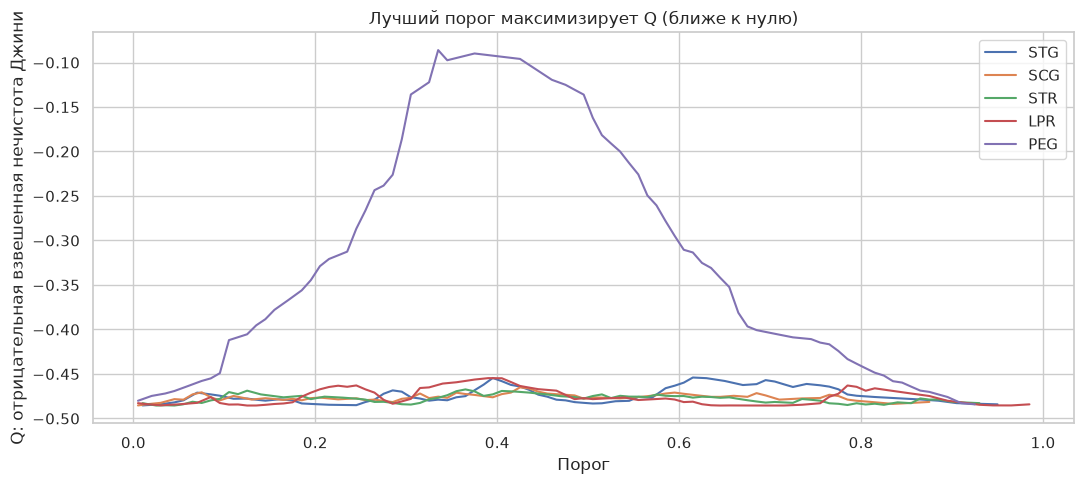

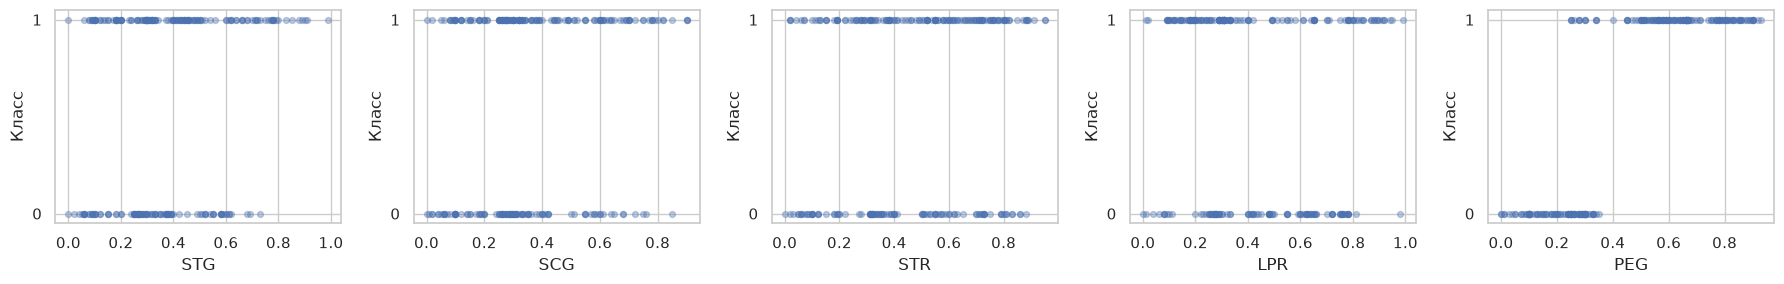

,признак,порог,критерий
4,PEG,0.335,-0.086066
0,STG,0.615,-0.453977
3,LPR,0.390,-0.454668
1,SCG,0.425,-0.465019
2,STR,0.365,-0.467338


In [ ]:
students=pd.read_csv('students.csv')
students.columns=students.columns.str.strip()
X_students=students.iloc[:,:5].to_numpy()
y_students=students.iloc[:,-1].to_numpy()

assert set(np.unique(y_students))=={0,1}

display(students.head())
best_splits=[]
plt.figure(figsize=(11,5))

for j,name in enumerate(students.columns[:5]):
    thresholds,ginis,threshold,best=find_best_split(X_students[:,j],y_students)
    plt.plot(thresholds,ginis,label=name)
    best_splits.append({'признак':name,'порог':threshold,'критерий':best})

plt.xlabel('Порог');plt.ylabel('Q: отрицательная взвешенная нечистота Джини')
plt.title('Лучший порог максимизирует Q (ближе к нулю)');plt.legend();plt.tight_layout();plt.show()

fig,axes=plt.subplots(1,5,figsize=(18,3))

for j,ax in enumerate(axes):
    ax.scatter(X_students[:,j],y_students,alpha=.35,s=18)
    ax.set(xlabel=students.columns[j],ylabel='Класс',yticks=[0,1])

plt.tight_layout();plt.show()
split_results=pd.DataFrame(best_splits).sort_values('критерий',ascending=False)

display(split_results)

**Вопрос**: Исходя из кривых значений критерия Джини, по какому признаку нужно производить деление выборки на два поддерева? Согласуется ли этот результат с визуальной оценкой scatter-графиков? Как бы вы охарактеризовали вид кривой для «хороших» признаков, по которым выборка делится почти идеально? Чем отличаются кривые для признаков, по которым деление практически невозможно?

**Ответ** Делить лучше по PEG: порог 0.335, Q примерно -0.086. У остальных признаков лучший Q около -0.45...-0.47.

На scatter PEG тоже лучше разделяет классы, хотя разделение не идеальное. У хорошего признака есть выраженный максимум Q близко к нулю, обе части становятся почти чистыми. У слабых признаков классы перемешаны и кривая не даёт заметного улучшения

Здесь Q отрицательный, поэтому выбираем максимум, не минимум

**Задание 5**. Разберитесь с уже написанным кодом в классе `DecisionTree` модуля `hw2code.py`. Найдите ошибки в реализации метода `_fit_node`. Напишите функцию `_predict_node`.

**Список найденных ошибок**:

1. ...
2. ...

Построение дерева осуществляется согласно базовому жадному алгоритму, предложенному в [лекции](https://github.com/esokolov/ml-course-hse/blob/master/2020-fall/lecture-notes/lecture07-trees.pdf) Е.А. Соколова в разделе «Построение дерева». Выбор лучшего разбиения необходимо производить по критерию Джини. Критерий останова: все объекты в листе относятся к одному классу или ни по одному признаку нельзя разбить выборку. Ответ в листе: наиболее часто встречающийся класс в листе. Для категориальных признаков выполняется преобразование, описанное в лекции в разделе «Учет категориальных признаков».

**Ответ** Список ошибок:

1. Проверка чистого листа через `!=` вместо `==` никогда не срабатывала: первый объект не может отличаться от самого себя
2. Перебор признаков начинался с 1, первый столбец пропускался
3. После сортировки брались доли, а нужны были названия категорий
4. `np.array(map(...))` создавал объект с итератором, а не массив рангов
5. Пропускались признаки при длине выборки 3. Проверять надо отсутствие допустимых порогов.
6. В лист записывался список (класс, частота), а нужен был сам класс
7. В правое поддерево передавались метки левого

**Задание 6**. Протестируйте свое решающее дерево на датасете [mushrooms](https://archive.ics.uci.edu/ml/datasets/Mushroom). Вам нужно скачать таблицу agaricus-lepiota.data, прочитать ее с помощью `pandas`, применить к каждому столбцу `LabelEncoder` (из `sklearn`), чтобы преобразовать строковые имена категорий в натуральные числа. Первый столбец — это целевая переменная (e — edible, p — poisonous). Мы будем измерять качество с помощью accuracy, так что нам не очень важно, что будет классом 1, а что — классом 0. Обучите решающее дерево на половине случайно выбранных объектов (признаки в датасете категориальные) и сделайте предсказания для оставшейся половины. Вычислите accuracy.

У вас должно получиться значение accuracy, равное единице (или очень близкое к единице), и не очень глубокое дерево.

In [9]:
mushrooms=pd.read_csv('data/agaricus-lepiota.data',header=None)
assert mushrooms.shape==(8124,23)

encoded_mushrooms=mushrooms.apply(lambda col:LabelEncoder().fit_transform(col))

X_mushrooms=encoded_mushrooms.iloc[:,1:].to_numpy()
y_mushrooms=encoded_mushrooms.iloc[:,0].to_numpy()

X_train,X_test,y_train,y_test=train_test_split(X_mushrooms,y_mushrooms,test_size=.5,stratify=y_mushrooms,random_state=SEED)

mushroom_tree=DecisionTree(['categorical']*X_train.shape[1]).fit(X_train,y_train)
mushroom_accuracy=accuracy_score(y_test,mushroom_tree.predict(X_test))

print(f'Accuracy train: {accuracy_score(y_train,mushroom_tree.predict(X_train)):.5f}')
print(f'Accuracy test: {mushroom_accuracy:.5f}; глубина: {mushroom_tree.get_depth()}')

assert mushroom_accuracy>.98

Accuracy train: 1.00000
Accuracy test: 1.00000; глубина: 7


**Задание 7**. Загрузите следующие наборы данных (`pandas` умеет загружать файлы по url, в нашем случае это файл \*.data), предварительно ознакомившись с описанием признаков и целевой переменной в каждом из них (она записаны в Data Folder, в файле \*.names):
* [mushrooms](https://archive.ics.uci.edu/ml/datasets/Mushroom) (загрузили в предыдущем пункте, классы записаны в нулевом столбце),
* [cars](https://archive.ics.uci.edu/ml/datasets/Car+Evaluation) (классы записаны в последнем столбце, считаем, что unacc, acc — это класс 0, good, vgood — класс 1),
* [nursery](https://archive.ics.uci.edu/ml/datasets/Nursery) (классы записаны в последнем столбце, считаем, что not_recom и recommend — класс 0, very_recom, priority, spec_prior — класс 1).

Закодируйте категориальные признаки, использовав `LabelEncoder`. С помощью `cross_val_score` (`cv=10`) оцените accuracy на каждом из этих наборов данных следующих алгоритмов:
* `DecisionTree`, считающий все признаки вещественными,
* `DecisionTree`, считающий все признаки категориальными,
* `DecisionTree`, считающий все признаки вещественными + one-hot-encoding всех признаков,
* `DecisionTreeClassifier` из `sklearn`.

Запишите результат в `pd.DataFrame` (по строкам — наборы данных, по столбцам — алгоритмы). Также было бы здорово, если представите компанктую и понятную визуализацию этих результатов.

Рекомендации:
* Чтобы `cross_val_score` вычисляла точность, нужно передать `scoring=make_scorer(accuracy_score)`, обе функции из `sklearn.metrics`.
* Если вам позволяет память (а она скорее всего позволяет), указывайте параметр `sparse_output=False` в `OneHotEncoder` (если вы, конечно, используете его). Иначе вам придется добиваться того, чтобы ваша реализация дерева умела работать с разреженными матрицами (что тоже, в целом, не очень сложно).

In [11]:
from sklearn.base import BaseEstimator, ClassifierMixin
class OneHotTree(ClassifierMixin, BaseEstimator):
    def fit(self,X,y):
        self.tree_=DecisionTree(['real']*X.shape[1]).fit(X,y)
        self.classes_=self.tree_.classes_
        self.n_features_in_=X.shape[1]
        return self
    def predict(self,X):
        return self.tree_.predict(X)


mushrooms, своё: числовые: 1.00000 ± 0.00000
mushrooms, своё: категории: 1.00000 ± 0.00000
mushrooms, своё: one-hot: 1.00000 ± 0.00000
mushrooms, sklearn: 1.00000 ± 0.00000
mushrooms, константа: 0.51797 ± 0.00046
cars, своё: числовые: 0.99189 ± 0.00696
cars, своё: категории: 0.99189 ± 0.00645
cars, своё: one-hot: 0.98842 ± 0.01098
cars, sklearn: 0.99189 ± 0.00696
cars, константа: 0.92246 ± 0.00277
nursery, своё: числовые: 0.99961 ± 0.00062
nursery, своё: категории: 0.99977 ± 0.00049
nursery, своё: one-hot: 0.99977 ± 0.00049
nursery, sklearn: 0.99969 ± 0.00062
nursery, константа: 0.66651 ± 0.00031


модель,sklearn,константа,своё: one-hot,своё: категории,своё: числовые
датасет,,,,,
cars,0.99189,0.92246,0.98842,0.99189,0.99189
mushrooms,1.00000,0.51797,1.00000,1.00000,1.00000
nursery,0.99969,0.66651,0.99977,0.99977,0.99961


модель,sklearn,константа,своё: one-hot,своё: категории,своё: числовые
датасет,,,,,
cars,0.00696,0.00277,0.01098,0.00645,0.00696
mushrooms,0.00000,0.00046,0.00000,0.00000,0.00000
nursery,0.00062,0.00031,0.00049,0.00049,0.00062


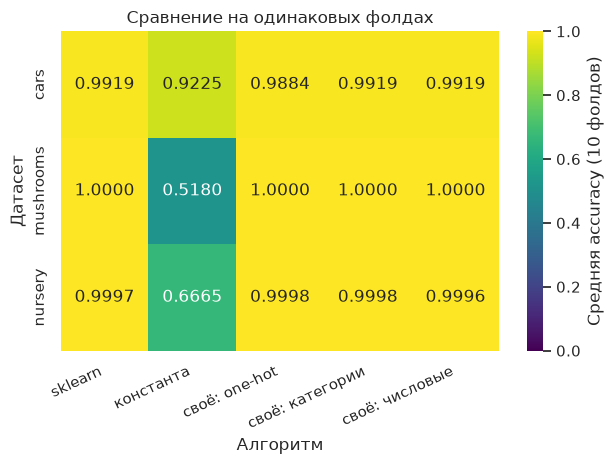

In [12]:
cars=pd.read_csv('data/car.data',header=None)
nursery=pd.read_csv('data/nursery.data',header=None)

assert cars.shape==(1728,7) and nursery.shape==(12960,9)

y_cars=cars.iloc[:,-1].map({'unacc':0,'acc':0,'good':1,'vgood':1})
y_nursery=nursery.iloc[:,-1].map({'not_recom':0,'recommend':0,'very_recom':1,'priority':1,'spec_prior':1})

assert y_cars.notna().all() and y_nursery.notna().all()

X_cars=cars.iloc[:,:-1].apply(lambda col:LabelEncoder().fit_transform(col)).to_numpy()
X_nursery=nursery.iloc[:,:-1].apply(lambda col:LabelEncoder().fit_transform(col)).to_numpy()

collections={'mushrooms':(X_mushrooms,y_mushrooms),'cars':(X_cars,y_cars.to_numpy()),'nursery':(X_nursery,y_nursery.to_numpy())}
score_rows=[]

for name,(X,y) in collections.items():
    folds=list(StratifiedKFold(n_splits=10,shuffle=True,random_state=SEED).split(X,y))
    models={
        'своё: числовые':DecisionTree(['real']*X.shape[1]),
        'своё: категории':DecisionTree(['categorical']*X.shape[1]),
        'своё: one-hot':Pipeline([('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False)),('tree',OneHotTree())]),
        'sklearn':DecisionTreeClassifier(random_state=SEED),
        'константа':DummyClassifier(strategy='most_frequent'),
    }

    for title,model in models.items():
        scores=cross_val_score(model,X,y,cv=folds,scoring=make_scorer(accuracy_score),error_score='raise')
        score_rows.append({'датасет':name,'модель':title,'accuracy':scores.mean(),'std':scores.std()})
        print(f'{name}, {title}: {scores.mean():.5f} ± {scores.std():.5f}',flush=True)

scores_table=pd.DataFrame(score_rows)
means=scores_table.pivot(index='датасет',columns='модель',values='accuracy')
stds=scores_table.pivot(index='датасет',columns='модель',values='std')

display(means.round(5));display(stds.round(5))

sns.heatmap(means,annot=True,fmt='.4f',vmin=0,vmax=1,cmap='viridis',cbar_kws={'label':'Средняя accuracy (10 фолдов)'})
plt.xlabel('Алгоритм');plt.ylabel('Датасет');plt.xticks(rotation=25,ha='right');plt.title('Сравнение на одинаковых фолдах');plt.tight_layout();plt.show()

**Вопрос**: Проанализируйте результаты эксперимента.
Одинаково ли для разных наборов данных ранжируются алгоритмы?
Порассуждайте, почему так происходит.

**Ответ** На mushrooms все четыре дерева получили accuracy=1. Тут ранжировать их по качеству не получается

На cars числовое, категориальное и sklearn дают около 0.9919, one-hot чуть ниже - 0.9884. Но разброс по фолдам больше этой разницы, поэтому однозначно хуже one-hot я бы не называл. Константа тут уже даёт 0.9225 из-за дисбаланса классов

На nursery категориальное дерево и one-hot дают около 0.99977, sklearn — 0.99969, числовое — 0.99961. Отличия очень маленькие, почти все объекты классифицируются правильно

Порядок алгоритмов не одинаковый. Номера LabelEncoder не означают порядок категорий, а числовое дерево использует именно его. Категориальное дерево может объединить категории по доле класса 1, one-hot выделяет их отдельными признаками. На разных задачах это приводит к разным делениям. При этом в nursery после объединения классов по условию почти всё определяется признаком health, поэтому задача становится очень простой

## Часть N.

Вставьте картинку, описывающую ваш опыт выполнения этого ДЗ.

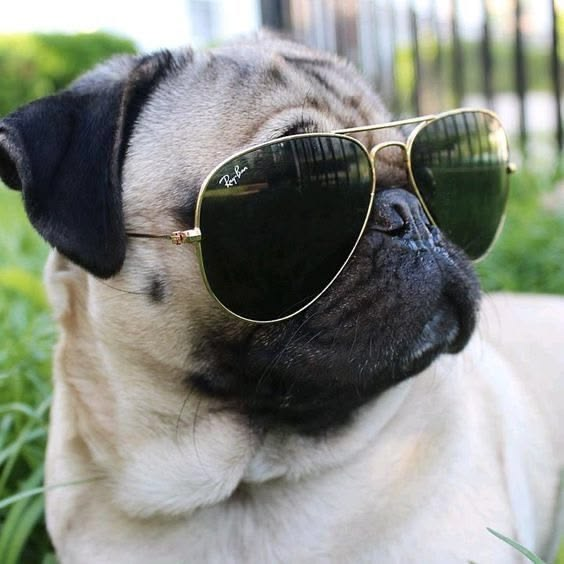

In [14]:
display(Image(filename="./assets/mops.jpg"))